### <b>10차시 미니 프로젝트 - 질문하고 그래프로 답하기</b>

* 처음 보는 데이터(캠퍼스 공유 자전거)로 질문 세 개에 그래프로 답한다.
* 먼저 직접 그려 보고, 질문마다 <b>정답 그래프</b>와 <b>그렇게 그리는 이유</b>, <b>조심할 점</b>을 확인한다.
* 마지막에 세 답을 1×3 요약 그림 한 장으로 묶어 저장하고 점검 목록으로 확인한다.

* 맨 위 코드 셀은 <b>준비 셀</b>이다. 구글 드라이브를 연결해 실습 폴더로 이동하고, 한글 폰트를 설치해 등록한다.
  * 구글 드라이브에 <b>데이터_시각화_실습</b> 폴더를 만들고, 그 안에 <b>data</b> 폴더를 올려 둔 뒤 실행한다.
  * 이번에는 추가 데이터 <b>bike_rentals.csv</b>를 data 폴더에 먼저 올려 둔다.
  * 내용은 고치지 않고 실행만 한다. 드라이브 접근을 묻는 창이 뜨면 허용한다. 출력에 CSV 파일 이름 세 개가 보이면 끝난 것이다.
  * 세션이 끊겨도 입력한 코드는 남아 있다. 이어서 할 셀을 선택하고 <b>런타임 › 이전 셀 실행</b>을 누르면 준비 셀부터 다시 실행된다.
* 나머지 코드 칸은 강의를 따라 입력한다. 주석(#)은 입력하지 않아도 되고, 앞 셀과 비슷한 코드는 복사해 고친다.

In [1]:
# keep
# 1. 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')

# 2. 실습 폴더로 기본 작업 위치 이동 (폴더명 변경 필요)
import os
os.chdir('/content/drive/MyDrive/데이터_시각화_실습')

# 3. 현재 위치 확인 (설정한 폴더 경로가 출력됨)
print("현재 작업 폴더:", os.getcwd())

# 4. 나눔고딕 폰트를 설치하고 Matplotlib에 등록
!apt-get -qq install -y fonts-nanum > /dev/null
from matplotlib import font_manager
font_manager.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

# 5. 실습 데이터 확인 (CSV 파일 이름 세 개가 출력됨)
!ls data

* 준비 셀 다음 셀에 6차시에서 정한 <b>설정 셀</b>을 그대로 입력한다.

In [2]:
# 표는 pandas, 그래프는 plt와 Seaborn으로 다룬다
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 테마와 한글 폰트를 함께 정한다
sns.set_theme(style='whitegrid', font='NanumGothic', rc={'axes.unicode_minus': False})

* <b>bike_rentals.csv</b>: 캠퍼스 공유 자전거 1년 일별 대여(가상). 하루 = 1행, 365행. 날씨는 카페 데이터와 같다.
  * <b>main_gate</b>(정문)·<b>library</b>(도서관)·<b>dorm</b>(기숙사)·<b>gym</b>(체육관): 대여소별 그날 대여 수
  * <b>rentals</b>: 네 곳 합계, <b>avg_temp</b>: 평균 기온(°C), <b>rain</b>: 비 온 날 1, <b>period</b>: 학사 기간

In [3]:
# 공유 자전거 CSV를 date 열은 날짜로 읽어 bike에 담는다
bike = pd.read_csv('data/bike_rentals.csv', parse_dates=['date'])
# 표의 행과 열 수를 출력한다
print(bike.shape)
# 앞 5행을 본다
bike.head()

(365, 12)


,date,year_month,month,weekday,period,avg_temp,rain,main_gate,library,dorm,gym,rentals
0,2025-03-01,2025-03,3,토,1학기,3.4,0,19,34,21,16,90
1,2025-03-02,2025-03,3,일,1학기,5.7,0,21,28,13,20,82
2,2025-03-03,2025-03,3,월,1학기,8.8,0,82,67,45,34,228
3,2025-03-04,2025-03,3,화,1학기,2.4,1,18,32,15,15,80
4,2025-03-05,2025-03,3,수,1학기,2.8,0,53,59,43,30,185


#### <b>미션: 질문 세 개에 그래프로 답하기</b>

* ① 어느 대여소에서 자전거를 가장 많이 빌릴까?
* ② 학기 중에는 기온이 오를수록 대여가 늘까? 비 오는 날은 어떨까?
* ③ 1년 동안 대여는 어떻게 달라질까?
* 질문마다 유형을 정하고, 표를 만들고, 알맞은 그래프를 그려 제목에 답을 쓴다. 아래 칸에서 직접 해 본 뒤 해설과 비교한다.

In [4]:
# 질문 ①을 직접 그려 보는 칸이다.

In [5]:
# 질문 ②를 직접 그려 보는 칸이다.

In [6]:
# 질문 ③을 직접 그려 보는 칸이다.

#### <b>해설 ① 어느 대여소에서 자전거를 가장 많이 빌릴까?</b>

* 문제: 대여소 네 곳 중 어디서 가장 많이 빌리는지 비교한다.
* 질문 유형: "어느 쪽이 더 큰가" → <b>비교</b>
* 먼저 네 열의 하루 평균을 구한다. 4차시 메뉴별 합계처럼 열 네 개를 골라 평균(mean)을 낸다.

In [7]:
# 대여소 네 열의 하루 평균 대여 수를 구한다
station_mean = bike[['main_gate', 'library', 'dorm', 'gym']].mean().round(2)
# index를 한글 대여소 이름으로 바꾼다
station_mean.index = ['정문', '도서관', '기숙사', '체육관']
# 작은 값부터 정렬한다
station_mean = station_mean.sort_values()
# 만든 표를 본다
station_mean

체육관    28.63
기숙사    36.56
정문     38.81
도서관    51.81
dtype: float64

* 같은 값을 파이 차트(왼쪽)와 정렬한 가로 막대(오른쪽)로 나란히 그려 비교한다.

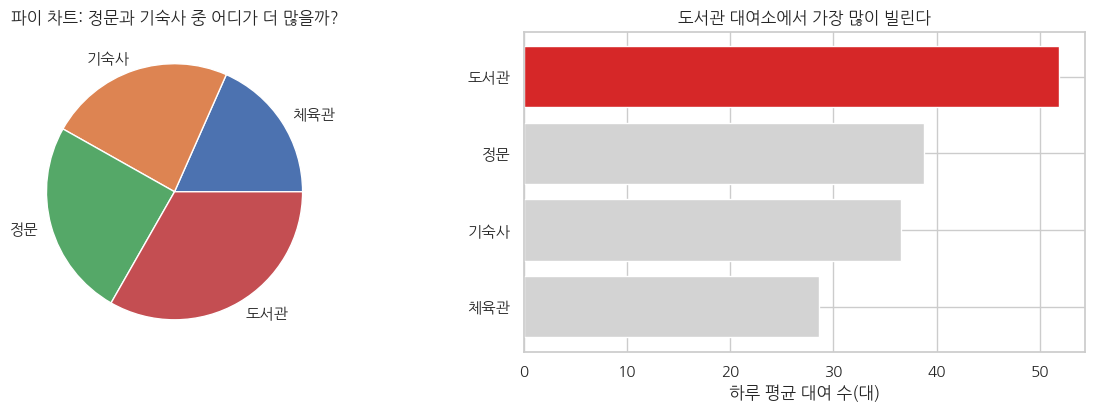

In [8]:
# 1행 2열 칸을 만든다
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
# 왼쪽 칸에 같은 값을 파이 차트로 그린다
axes[0].pie(station_mean.values, labels=station_mean.index)
axes[0].set_title('파이 차트: 정문과 기숙사 중 어디가 더 많을까?')
# 가장 큰 대여소만 빨강, 나머지는 회색으로 정한다
colors = ['#d62728' if v == station_mean.max() else 'lightgray' for v in station_mean.values]
# 오른쪽 칸에 정렬한 가로 막대를 그린다
axes[1].barh(station_mean.index, station_mean.values, color=colors)
# 오른쪽 칸에 답을 제목으로 쓰고 x축 이름을 단다
axes[1].set_title('도서관 대여소에서 가장 많이 빌린다')
axes[1].set_xlabel('하루 평균 대여 수(대)')
# 그래프를 화면에 보여 준다
plt.show()

* <b>정답</b>: 정렬한 가로 막대, 가장 많은 도서관만 강조색. 제목 "도서관 대여소에서 가장 많이 빌린다"
  * 도서관 51.81대 > 정문 38.81대 > 기숙사 36.56대 > 체육관 28.63대
* <b>이렇게 그리는 이유</b>
  * 비교는 길이로 읽는 막대가 가장 정확하다. 정렬하면 막대 순서가 곧 순위다.
  * 파이 차트는 각도와 넓이로 읽는다. 정문과 기숙사처럼 비슷한 조각은 어느 쪽이 큰지 구분이 안 된다.
  * 강조색 하나가 답(도서관)을 가리키고, 나머지는 회색으로 물러난다(5차시).
* <b>조심할 점</b>
  * 가로 막대는 첫 값을 맨 아래에 그린다. 큰 값이 위로 오게 작은 값부터 정렬한다(4차시).
  * index에 한글 이름을 넣을 때는 열 순서(정문·도서관·기숙사·체육관)와 같게 넣는다. 정렬은 이름을 바꾼 다음에 한다.
  * 합계가 아니라 하루 평균으로 비교해도 순위는 같다. 날 수가 모두 365일이기 때문이다.
  * 막대는 0에서 시작해야 길이 비율이 맞다. x축 범위를 자르지 않는다.

#### <b>해설 ② 학기 중에는 기온이 오를수록 대여가 늘까? 비 오는 날은 어떨까?</b>

* 문제: 학기 중 날만 보고, 기온과 대여 수가 함께 움직이는지, 비 오는 날은 어떤지 본다.
* 질문 유형: "두 값이 함께 움직이나" → <b>관계</b>
* 표 준비
  * 질문의 "학기 중"을 필터로 옮긴다. 1학기·2학기 날만 고르고, 새 열을 만들 것이라 <b>copy()</b>로 떼어 둔다.
  * rain의 0·1을 <b>map(사전)</b>으로 '맑은 날'·'비 온 날' 글자로 바꾼 열을 만든다. 범례에 뜻이 보이게 하기 위해서다.

In [9]:
# 학기 중 날만 골라 따로 떼어 둔다
semester = bike[bike['period'].isin(['1학기', '2학기'])].copy()
# 비 여부를 글자로 바꾼 열을 만든다
semester['weather'] = semester['rain'].map({0: '맑은 날', 1: '비 온 날'})
# 학기 중 날 수를 출력한다
print(len(semester))
# 맑은 날의 기온과 대여 수의 상관계수를 출력한다
sunny = semester[semester['weather'] == '맑은 날']
print(round(sunny['avg_temp'].corr(sunny['rentals']), 2))
# 날씨별 날 수와 평균 대여 수를 본다
semester.groupby('weather')['rentals'].agg(['count', 'mean']).round(2)

222
0.71


,count,mean
weather,,
맑은 날,166,246.92
비 온 날,56,102.50


* 날짜 순 선 그래프(왼쪽)와 기온-대여 수 산점도(오른쪽)를 나란히 그려 비교한다.

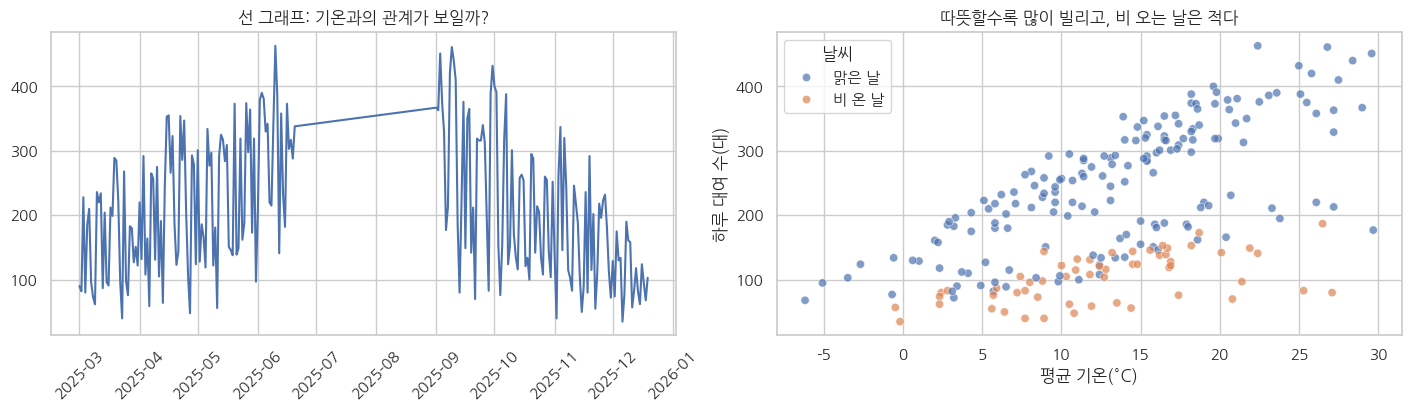

In [10]:
# 1행 2열 칸을 만든다
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout='constrained')
# 왼쪽 칸에 날짜 순서대로 대여 수를 선으로 그린다
axes[0].plot(semester['date'], semester['rentals'])
axes[0].set_title('선 그래프: 기온과의 관계가 보일까?')
axes[0].tick_params(axis='x', labelrotation=45)
# 오른쪽 칸에 기온과 대여 수의 산점도를 날씨로 색을 나눠 그린다
sns.scatterplot(data=semester, x='avg_temp', y='rentals', hue='weather', alpha=0.7, ax=axes[1])
# 오른쪽 칸에 답을 제목으로 쓰고 축 이름과 범례 제목을 단다
axes[1].set_title('따뜻할수록 많이 빌리고, 비 오는 날은 적다')
axes[1].set_xlabel('평균 기온(°C)')
axes[1].set_ylabel('하루 대여 수(대)')
axes[1].legend(title='날씨')
# 그래프를 화면에 보여 준다
plt.show()

* <b>정답</b>: 학기 중 날만 고른 기온-대여 수 산점도, 날씨로 색을 나눔. 제목 "따뜻할수록 많이 빌리고, 비 오는 날은 적다"
  * 학기 중 222일. 맑은 날 166일은 하루 평균 246.92대, 비 온 날 56일은 102.50대
  * 맑은 날 기온과 대여 수의 상관계수 0.71: 함께 커지는 관계가 뚜렷하다(8차시).
* <b>이렇게 그리는 이유</b>
  * 관계는 두 값을 두 축에 놓아야 보인다. 산점도는 기온을 x, 대여 수를 y에 놓아 점이 오른쪽 위로 오르는지 바로 보여 준다.
  * 날짜 순 선 그래프에는 기온이 없다. 오르내림은 보이지만 "기온이 오르면 늘까"에는 답할 수 없다.
  * 질문에 비 오는 날이 함께 있으므로 hue로 색을 나눈다. 비 온 날 점은 같은 기온에서도 아래쪽에 몰려 있다.
* <b>조심할 점</b>
  * 방학까지 넣으면 학사 일정 때문에 점이 두 띠로 갈려 관계가 흐려진다(4차시 기온과 손님 수). 질문의 조건대로 학기 중만 고른다.
  * 필터한 표에 새 열을 바로 만들면 SettingWithCopyWarning이 난다(2차시). copy()로 떼어 둔다.
  * rain을 그대로 hue에 넣으면 범례가 0·1로 나와 뜻을 알 수 없다. 글자로 바꾼 열을 쓴다.
  * 맑은 날 점 중 아래쪽에 따로 모인 띠는 주말이다(맑은 학기 중 평일 평균 285.6대, 주말 145.9대). 기온 말고 요일도 대여 수를 바꾼다.
  * 점이 함께 오른다고 기온이 원인이라고 단정하지 않는다(8차시). "따뜻한 날 더 많이 빌린다"까지만 말한다.

#### <b>해설 ③ 1년 동안 대여는 어떻게 달라질까?</b>

* 문제: 1년 동안 대여 수가 언제 늘고 줄었는지 흐름을 본다.
* 질문 유형: "시간에 따라 어떻게 변하나" → <b>추이</b>
* 일별은 요일 때문에 너무 촘촘하므로 월별로 묶는다(3차시). "얼마나 빌렸나"이므로 평균 대신 한 달 합계(sum)를 낸다.

In [11]:
# 월별 대여 수 합계를 구한다
monthly = bike.groupby('year_month')['rentals'].sum()
# 만든 표를 본다
monthly

year_month
2025-03    4824
2025-04    6300
2025-05    7084
2025-06    7203
2025-07    3839
2025-08    3497
2025-09    8859
2025-10    6410
2025-11    5006
2025-12    2391
2026-01     687
2026-02     771
Name: rentals, dtype: int64

* 같은 표를 크기순으로 정렬한 막대(왼쪽)와 월 순서 선 그래프(오른쪽)로 나란히 그려 비교한다.

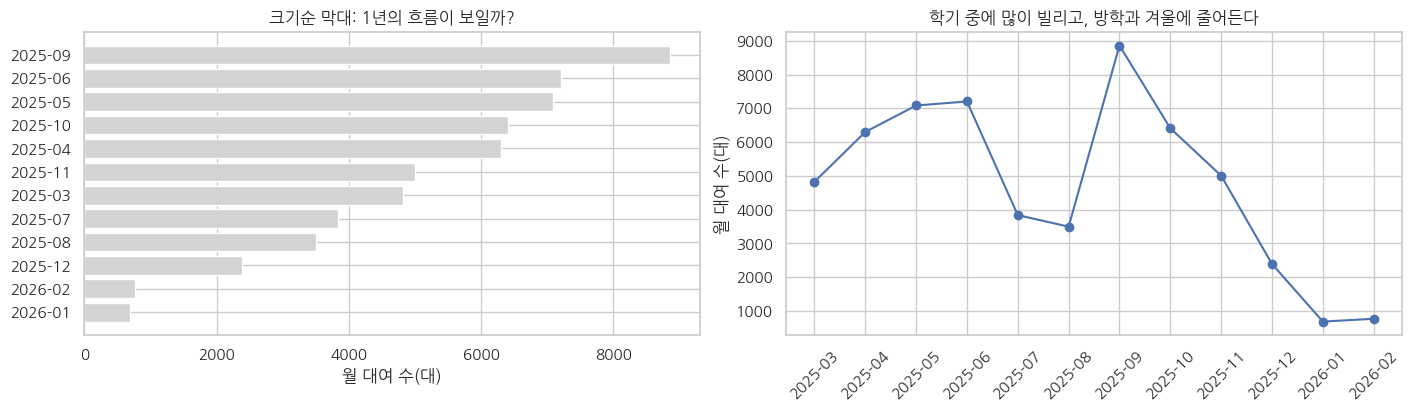

In [12]:
# 1행 2열 칸을 만든다
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout='constrained')
# 왼쪽 칸에 크기순으로 정렬한 가로 막대를 그린다
monthly_sorted = monthly.sort_values()
axes[0].barh(monthly_sorted.index, monthly_sorted.values, color='lightgray')
axes[0].set_title('크기순 막대: 1년의 흐름이 보일까?')
axes[0].set_xlabel('월 대여 수(대)')
# 오른쪽 칸에 월 순서대로 점이 있는 선을 그린다
axes[1].plot(monthly.index, monthly.values, marker='o')
axes[1].tick_params(axis='x', labelrotation=45)
# 오른쪽 칸에 답을 제목으로 쓰고 y축 이름을 단다
axes[1].set_title('학기 중에 많이 빌리고, 방학과 겨울에 줄어든다')
axes[1].set_ylabel('월 대여 수(대)')
# 그래프를 화면에 보여 준다
plt.show()

* <b>정답</b>: 월 순서대로 점을 찍어 이은 선 그래프. 제목 "학기 중에 많이 빌리고, 방학과 겨울에 줄어든다"
  * 3~6월에 늘었다가 7·8월 여름방학에 줄고, 2025-09가 8,859대로 가장 많다.
  * 9월이 지나면 날이 추워지며 줄고, 2026-01이 687대로 가장 적다.
* <b>이렇게 그리는 이유</b>
  * 추이는 시간 순서가 생명이다. 선은 달 순서대로 이어져 언제 늘고 줄었는지 보인다.
  * 크기순 막대는 어느 달이 많은지는 보이지만 달 순서가 섞여 흐름이 사라진다. 같은 표라도 질문이 "순위"면 막대, "흐름"이면 선이다.
  * 값이 12개뿐이라 marker='o'로 점을 찍어야 어느 달인지 보인다(3차시).
* <b>조심할 점</b>
  * year_month는 '2025-03' 같은 글자라 그대로 정렬해도 시간 순서가 맞는다. 크기순 정렬(sort_values)을 하면 순서가 깨진다.
  * 달마다 날 수가 다르다(2월 28일, 3월 31일). 합계는 날 수만큼 조금 차이가 나므로, 그보다 훨씬 큰 변화만 읽는다.
  * x축 글자 12개가 겹치면 기울인다(5차시 tick_params).
  * 선 그래프의 y축은 0에서 시작하지 않아도 된다. 막대가 아니라 위치로 읽기 때문이다(7차시).

#### <b>세 답을 한 장으로 모아 저장하고 점검하기</b>

* 해설에서 고른 정답 그래프 세 개만 5차시 <b>plt.subplots(1, 3)</b>으로 한 장에 모은다. 비교용으로 그린 그래프는 넣지 않는다.
  * Matplotlib 함수는 <b>axes[i]</b>에 대고, Seaborn 함수는 <b>ax=axes[i]</b>로 칸을 정한다(6차시).
  * 칸 제목은 답이다. 앞에 1. 2. 3.을 붙여 질문 번호와 맞춘다.
* 저장 폴더 <b>output</b>을 먼저 만들고, <b>plt.show()</b> 앞에서 <b>fig.savefig</b>로 저장한다(5차시).

In [13]:
# 폴더를 다루는 os 모듈을 불러온다
import os

# output 폴더를 만든다. 이미 있으면 넘어간다
os.makedirs('output', exist_ok=True)

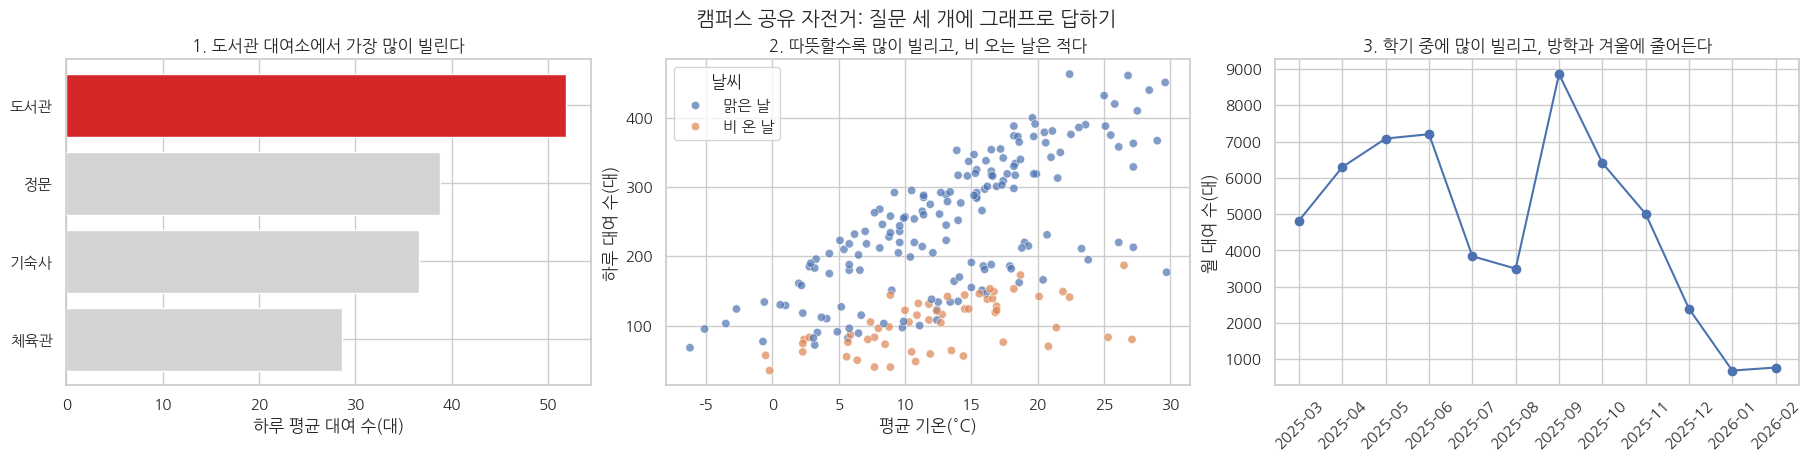

In [14]:
# 1행 3열 칸을 옆으로 넓게 만든다
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), layout='constrained')

# 1. 비교: 정렬한 가로 막대, 가장 큰 대여소만 강조한다
axes[0].barh(station_mean.index, station_mean.values, color=colors)
axes[0].set_title('1. 도서관 대여소에서 가장 많이 빌린다')
axes[0].set_xlabel('하루 평균 대여 수(대)')

# 2. 관계: 학기 중 기온과 대여 수의 산점도, 날씨로 색을 나눈다
sns.scatterplot(data=semester, x='avg_temp', y='rentals', hue='weather', alpha=0.7, ax=axes[1])
axes[1].set_title('2. 따뜻할수록 많이 빌리고, 비 오는 날은 적다')
axes[1].set_xlabel('평균 기온(°C)')
axes[1].set_ylabel('하루 대여 수(대)')
axes[1].legend(title='날씨')

# 3. 추이: 월별 합계를 시간 순서대로 이은 선
axes[2].plot(monthly.index, monthly.values, marker='o')
axes[2].tick_params(axis='x', labelrotation=45)
axes[2].set_title('3. 학기 중에 많이 빌리고, 방학과 겨울에 줄어든다')
axes[2].set_ylabel('월 대여 수(대)')

# 칸 전체 위에 제목을 단다
fig.suptitle('캠퍼스 공유 자전거: 질문 세 개에 그래프로 답하기')
# 해상도와 여백을 정해 저장한다
fig.savefig('output/bike_summary.png', dpi=200, bbox_inches='tight')
# 그래프를 화면에 보여 준다
plt.show()

* 파일은 드라이브의 실습 폴더 안 <b>output</b> 폴더에 <b>bike_summary.png</b>로 생긴다.
* 점검 다섯 가지
  * <b>제목 = 결론</b>: 칸 제목 세 개가 모두 답 문장이다.
  * <b>축 이름과 단위</b>: 대여 수(대), 기온(°C)처럼 무엇을 어떤 단위로 쟀는지 적었다.
  * <b>막대는 0부터</b>: 1번 막대는 0에서 시작한다. 점(2번)과 선(3번)은 아니어도 된다.
  * <b>색에 뜻이 있고 범례가 있다</b>: 1번은 빨강 하나가 가장 많은 대여소, 2번은 범례가 날씨를 알려 준다.
  * <b>한글·마이너스가 정상이다</b>: 글자가 네모로 나오면 설정 셀을 다시 실행한다.
* 정리: 질문을 읽고 → 유형을 정하고 → 표를 만들고 → 알맞은 그래프를 골라 → 제목에 답을 쓰고 → 점검해 저장한다. 그래프는 질문에 답하는 그림이다.